In [1]:
import numpy as np
import torch
import torch.nn as nn
import timm
from torchvision import transforms
from torchvision.datasets import ImageFolder
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

C:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
train_path = "cards/train"
test_path = "cards/test"

transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
])

train_data = ImageFolder(train_path, transform=transform)
test_data = ImageFolder(test_path, transform=transform)

class_names = train_data.classes
print("train", len(train_data))
print("test", len(test_data))
print("classes", len(class_names))

train 7624
test 265
classes 53


In [3]:
base_model = timm.create_model("efficientnet_b0", pretrained=True)

features = nn.Sequential(*list(base_model.children())[:-1])
features.eval()

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (1): BatchNormAct2d(
    32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True
    (drop): Identity()
    (act): SiLU(inplace=True)
  )
  (2): Sequential(
    (0): Sequential(
      (0): DepthwiseSeparableConv(
        (conv_dw): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
        (bn1): BatchNormAct2d(
          32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True
          (drop): Identity()
          (act): SiLU(inplace=True)
        )
        (aa): Identity()
        (se): SqueezeExcite(
          (conv_reduce): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
          (act1): SiLU(inplace=True)
          (conv_expand): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
          (gate): Sigmoid()
        )
        (conv_pw): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
       

In [4]:
train_features = []
train_labels = []

for i in range(len(train_data)):
    image, label = train_data[i]
    x = image.unsqueeze(0)
    
    with torch.no_grad():
        f = features(x)
        
    train_features.append(f[0].numpy())
    train_labels.append(label)

    if i % 500 == 0:
        print("train", i, "/", len(train_data))

train_features = np.array(train_features)
train_labels = np.array(train_labels)
print(train_features.shape)

train 0 / 7624
train 500 / 7624
train 1000 / 7624
train 1500 / 7624
train 2000 / 7624
train 2500 / 7624
train 3000 / 7624
train 3500 / 7624
train 4000 / 7624
train 4500 / 7624
train 5000 / 7624
train 5500 / 7624
train 6000 / 7624
train 6500 / 7624
train 7000 / 7624
train 7500 / 7624
(7624, 1280)


In [5]:
test_features = []
test_labels = []

for i in range(len(test_data)):
    image, label = test_data[i]
    x = image.unsqueeze(0)
    with torch.no_grad():
        f = features(x)
    test_features.append(f[0].numpy())
    test_labels.append(label)

test_features = np.array(test_features)
test_labels = np.array(test_labels)
print(test_features.shape)

(265, 1280)


In [6]:
def cosine(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

K = 5   # num of similar img
predictions = []

for i in range(len(test_features)):
    test_vector = test_features[i]

    similarities = []
    
    for j in range(len(train_features)):
        s = cosine(test_vector, train_features[j])
        similarities.append(s)
        
    similarities = np.array(similarities)

    best_indexes = np.argsort(similarities)[-K:]

    class_scores = {}
    for idx in best_indexes:
        c = train_labels[idx]
        
        if c not in class_scores:
            class_scores[c] = 0
            
        class_scores[c] = class_scores[c] + similarities[idx]

    best_class = max(class_scores, key=class_scores.get)
    predictions.append(best_class)

predictions = np.array(predictions)

In [7]:
print(classification_report(test_labels, predictions, target_names=class_names, zero_division=0))

                   precision    recall  f1-score   support

     ace of clubs       0.50      0.60      0.55         5
  ace of diamonds       0.60      0.60      0.60         5
    ace of hearts       0.27      0.60      0.38         5
    ace of spades       0.71      1.00      0.83         5
   eight of clubs       0.67      0.40      0.50         5
eight of diamonds       0.33      0.20      0.25         5
  eight of hearts       0.43      0.60      0.50         5
  eight of spades       0.50      0.40      0.44         5
    five of clubs       0.12      0.20      0.15         5
 five of diamonds       0.27      0.60      0.38         5
   five of hearts       0.00      0.00      0.00         5
   five of spades       0.20      0.20      0.20         5
    four of clubs       0.00      0.00      0.00         5
 four of diamonds       0.67      0.40      0.50         5
   four of hearts       0.20      0.20      0.20         5
   four of spades       0.33      0.20      0.25       

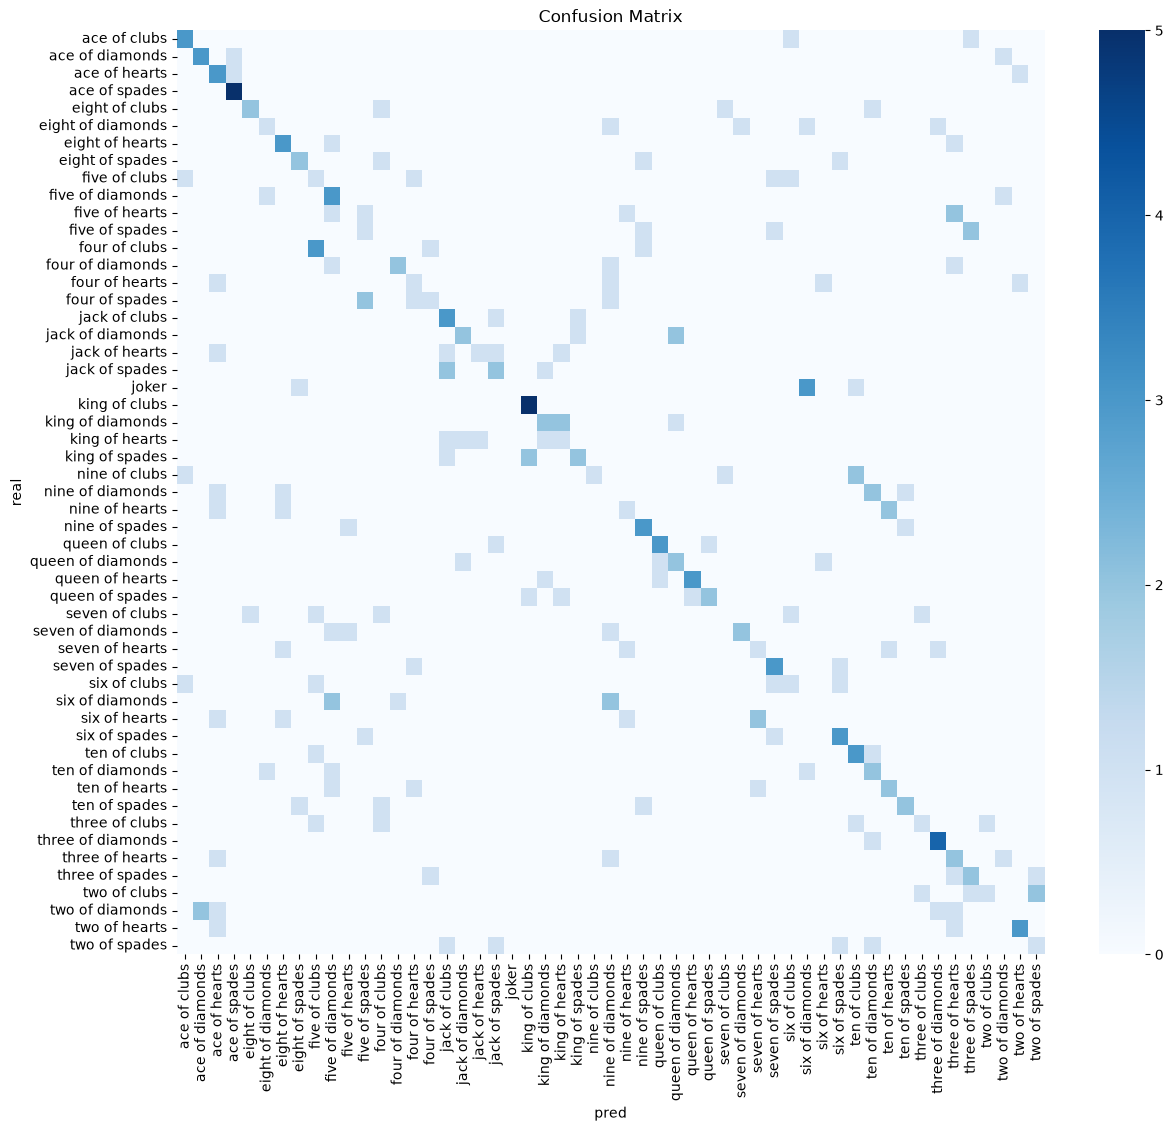

In [9]:
cm = confusion_matrix(test_labels, predictions)

plt.figure(figsize=(14, 12))
sns.heatmap(cm, cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("pred")
plt.ylabel("real")
plt.title("Confusion Matrix")
plt.show()
